# 01 - Data Preprocessing and Exploratory Data Analysis

Dataset: Criteo Uplift Prediction Dataset v2.1 (13,979,592 observations from a randomized
incrementality experiment, downloaded from Criteo's public research mirror).

This notebook presents the outputs of `scripts/01_eda_and_causal_inference.py` (run on the FULL dataset).

In [1]:
import pandas as pd
from IPython.display import Image, display
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
from src.utils.config import TABLES_DIR, FIGURES_DIR, REPORT_DIR

## Dataset Overview

In [2]:
pd.read_csv(TABLES_DIR / "dataset_overview.csv")

,metric,value
0,n_rows,1.397959e+07
1,n_features,1.200000e+01
2,treatment_ratio,8.500001e-01
3,control_ratio,1.499999e-01
4,overall_conversion_rate,2.916680e-03
5,overall_visit_rate,4.699200e-02
6,conversion_rate_treatment,3.089461e-03
7,conversion_rate_control,1.937588e-03
8,visit_rate_treatment,4.854336e-02
9,visit_rate_control,3.820096e-02


## Preprocessing Note: Duplicate Rows Are Not Data Errors

Raw validation found about 1.66M exact-duplicate rows (11.8%). Several anonymized features have low
cardinality (`f1`: 60 unique values, `f4`: 260, `f11`: 136), so repeated feature combinations are expected
in a dataset of this size. The analysis retains these observations because there is no row identifier that
would establish that they are accidental duplicate records.

## Naive (Unadjusted) Treatment-vs-Control Gap

In [3]:
import json
results = json.loads((REPORT_DIR / "phase1_results.json").read_text())
pd.DataFrame([results["naive_lift_conversion"], results["naive_lift_visit"]])

,outcome,treated_rate,control_rate,absolute_lift,relative_lift_pct,n_treated,n_control
0,conversion,0.003089,0.001938,0.001152,59.448812,11882655,2096937
1,visit,0.048543,0.038201,0.010342,27.073676,11882655,2096937


## Treatment & Outcome Distributions

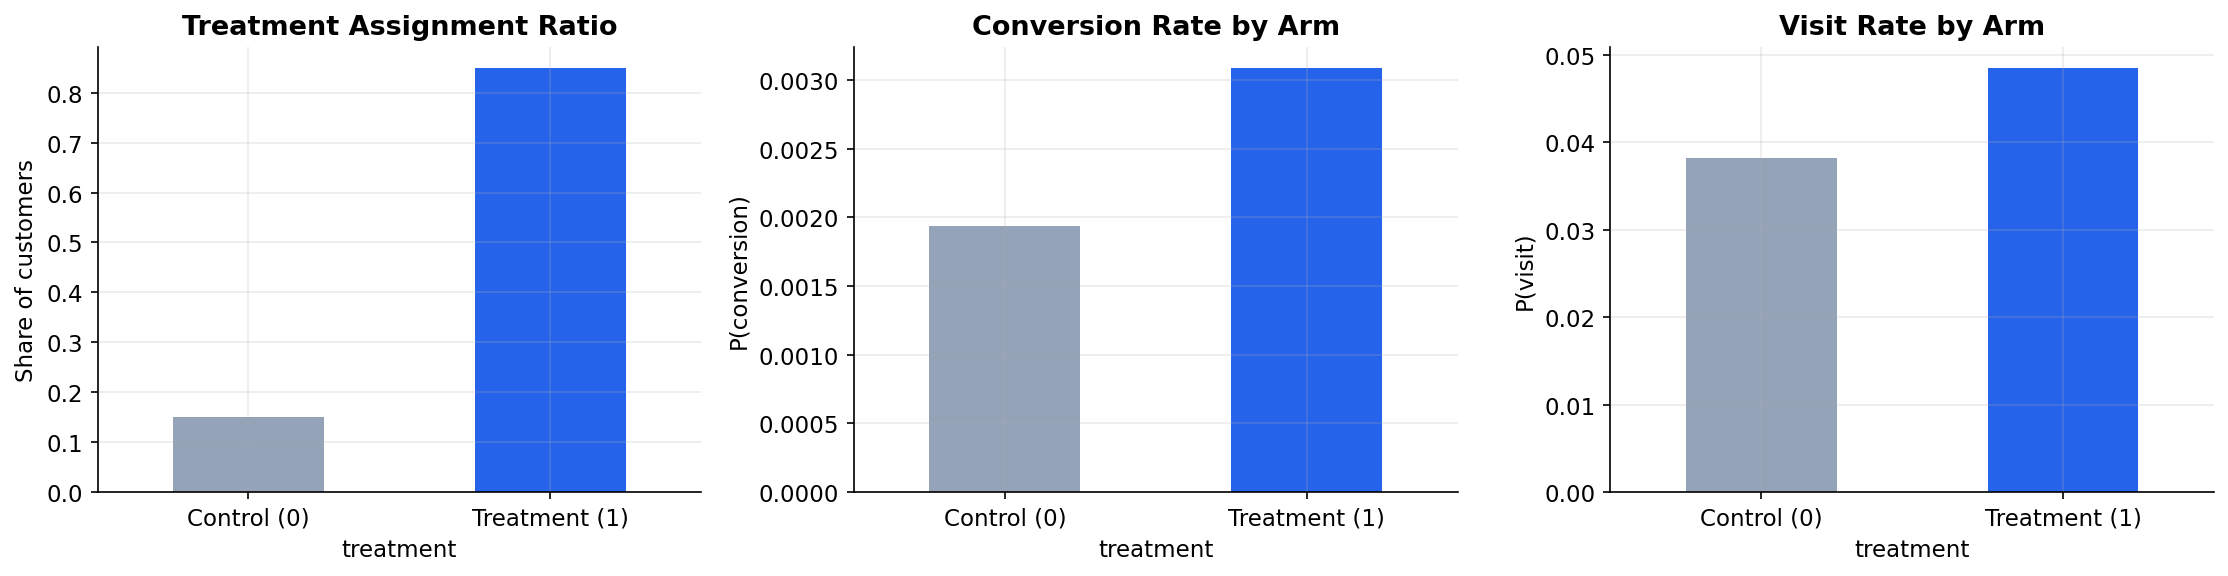

In [4]:
display(Image(filename=str(FIGURES_DIR / "treatment_outcome_distribution.png")))

## Feature Distributions by Arm

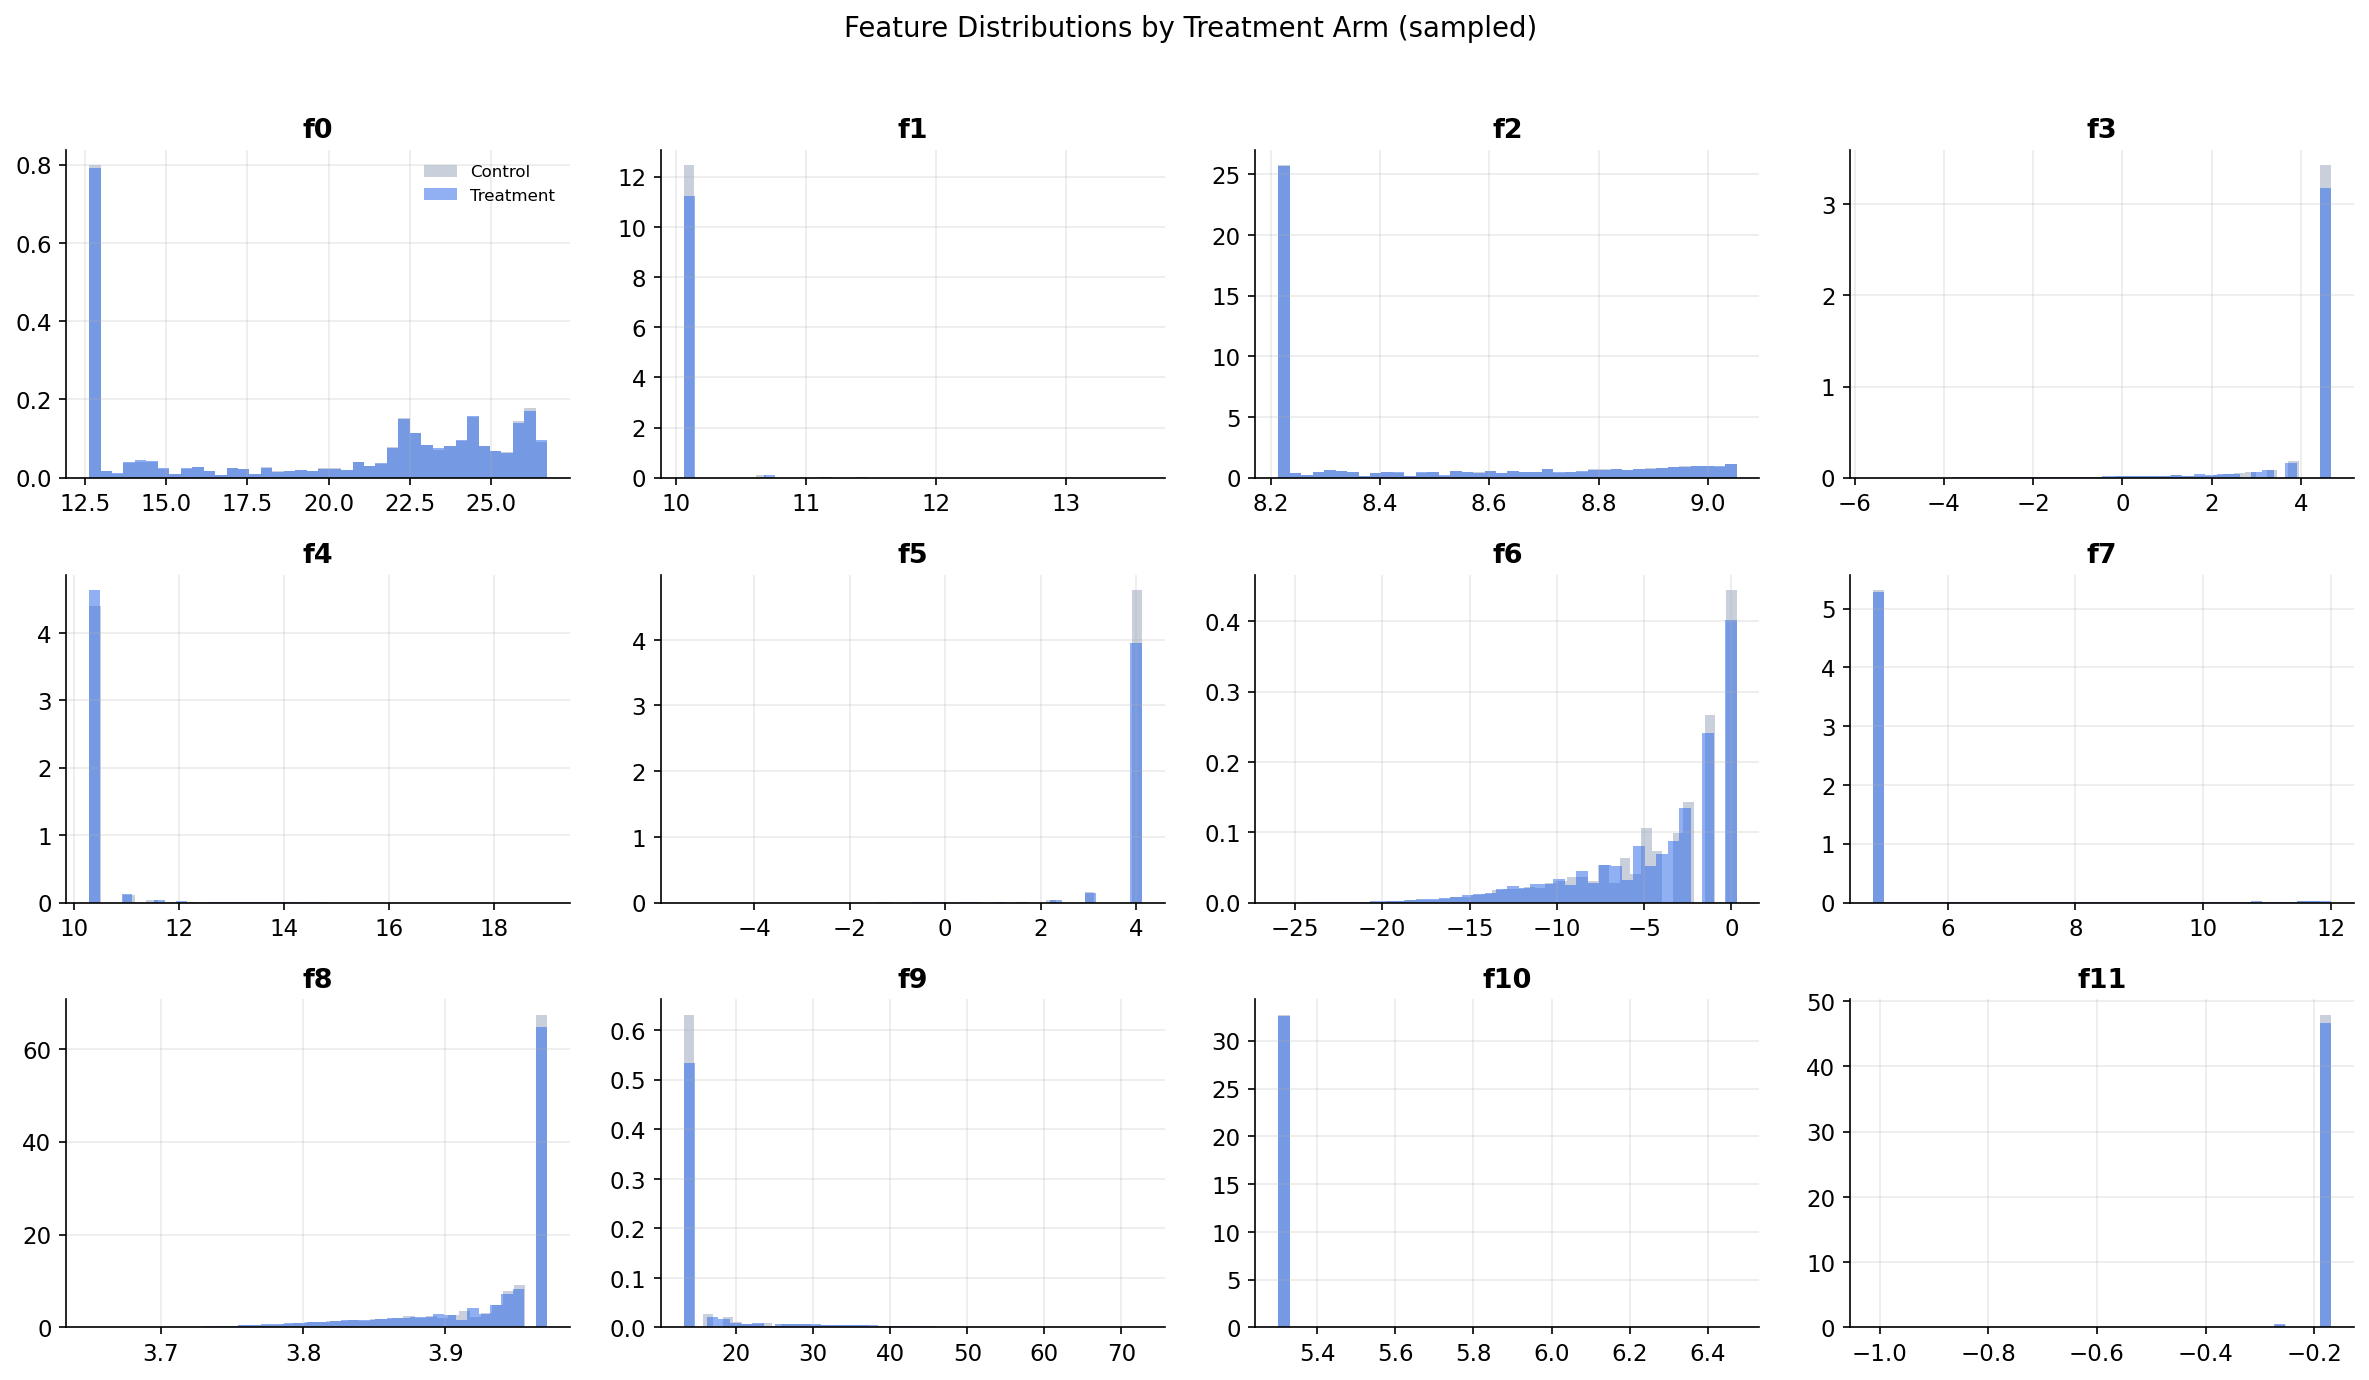

In [5]:
display(Image(filename=str(FIGURES_DIR / "feature_distributions_by_arm.png")))

## Feature / Treatment / Outcome Correlation

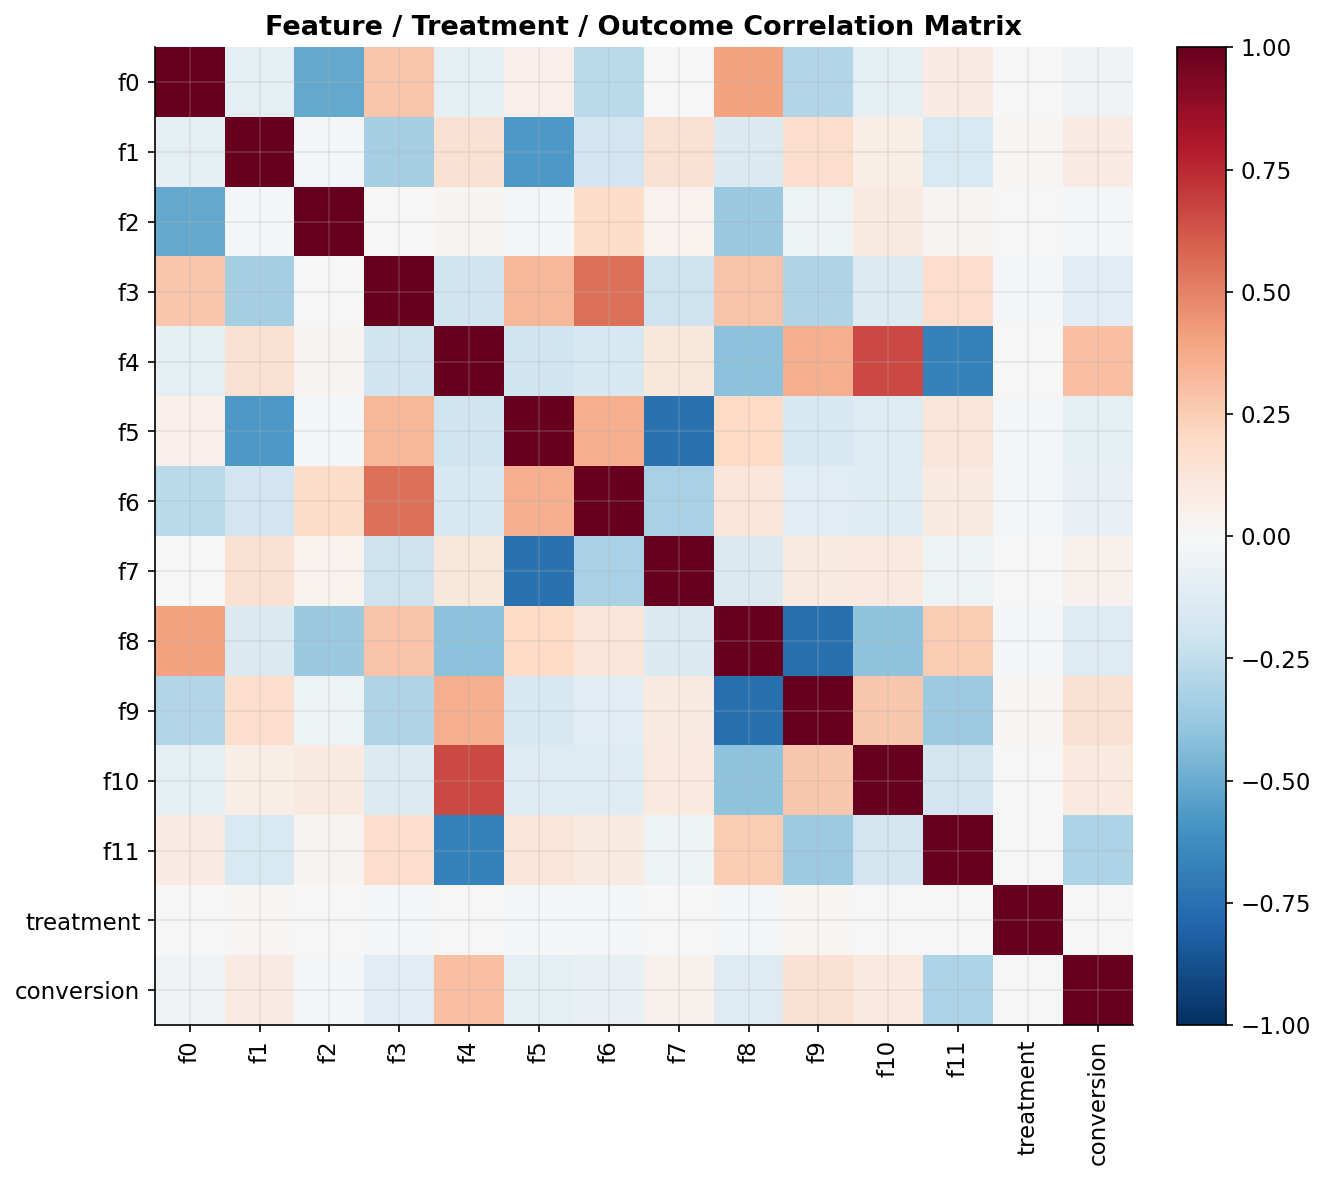

In [6]:
display(Image(filename=str(FIGURES_DIR / "feature_correlation_matrix.png")))

In [7]:
pd.read_csv(TABLES_DIR / "feature_correlation_matrix.csv", index_col=0)["conversion"].drop(["conversion","visit"], errors="ignore").sort_values(key=abs, ascending=False)

f11         -0.312184
f4           0.298634
f9           0.156245
f8          -0.130566
f3          -0.104222
f10          0.098295
f5          -0.086751
f1           0.083103
f6          -0.071954
f7           0.043745
f0          -0.037973
f2          -0.014175
treatment    0.007627
Name: conversion, dtype: float64

## Discussion: Potential Biases Observed

- Treatment is imbalanced (85% treated and 15% control). The smaller control arm increases the uncertainty
  of estimates that depend heavily on control observations.
- Conversion is rare (about 0.29% overall). This limits the precision of subgroup and uplift estimates even
  with a large dataset.
- `f11` and `f4` have the largest marginal correlations with conversion (approximately -0.31 and +0.30).
  They are used in the semi-synthetic confounding experiment in notebook 02.